# Data Audit and Hygiene

**Objective**  
Audit the raw survey database, apply response-quality and eligibility checks, and export a cleaned database for subsequent analysis.

**Agenda**
1. Setup and Data Ingestion
2. Speeders Check
3. Geographic Targeting Check
4. Age Criteria Check (18–65 Years)
5. Satisficers / Avoiders
6. Target Audience Screening
7. Survey Completion Check
8. Data Hygiene Summary and Export

###  1. Setup and Data Ingestion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# display settings for high-dimensional dataset
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 20)

In [3]:
DATA_PATH = '../data/P1_FTD_experiment.csv'

In [4]:
# Load raw dataset. Low_memory=False handles mixed types across columns
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df_raw.head(5)

,Participant ID,Flow,Status,Study time,Audience,Country,Region – Netherlands,"Q1. Which of the following have you done in the last 12 months, even if only once? Purchased access to online video games","Q1. Which of the following have you done in the last 12 months, even if only once? Made in-game purchases or bought loot boxes","Q1. Which of the following have you done in the last 12 months, even if only once? Deposited funds to cryptocurrency exchanges or digital wallets","Q1. Which of the following have you done in the last 12 months, even if only once? Purchased airline tickets online","Q1. Which of the following have you done in the last 12 months, even if only once? Booked travel accommodations online","Q1. Which of the following have you done in the last 12 months, even if only once? Deposited funds to online investment or brokerage accounts","Q1. Which of the following have you done in the last 12 months, even if only once? Purchased online educational courses or webinars","Q1. Which of the following have you done in the last 12 months, even if only once? Paid for adult video or content","Q1. Which of the following have you done in the last 12 months, even if only once? Deposited funds to online trading or contract platforms","Q1. Which of the following have you done in the last 12 months, even if only once? Made donations to charity","Q1. Which of the following have you done in the last 12 months, even if only once? None of these",Q1. Thank you for participating! The survey will take about 10 minutes.\nThere are no right or wrong answersjust share what feels right to you. Your responses are anonymous and will be processed in aggregate.,Q2. How old are you? (Please enter your age in full years) Answer,Q3. What is your gender? Answer,"Q4. Which of the following have you done in the last 3 months, even if only once? Deposited funds to online investment or brokerage accounts","Q4. Which of the following have you done in the last 3 months, even if only once? Deposited funds to cryptocurrency exchanges or digital wallets","Q4. Which of the following have you done in the last 3 months, even if only once? Deposited funds to online trading or contract platforms","Q4. Which of the following have you done in the last 3 months, even if only once? Purchased access to online video games",...,"Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? Virtual credit or debit cards (Visa, Mastercard, American Express, etc.)","Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? PayPal","Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? Apple Pay","Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? Google Pay","Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? IDEAL","Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? Tikkie","Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? Klarna","Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? AfterPay (Clearpay)","Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? Mastercard Click to Pay (Masterpass)","Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? Amazon Pay","Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? Billink","Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? Meta Pay (Facebook)","Q36. Which payment services do you prefer to use for online investment, crypto, or trading platforms? Visa Checkout","Q36. Which payment services do you prefer to use for online investment, crypto, or tradin

In [5]:
raw_n = df_raw.shape[0]
print (f'Raw table contains {raw_n} sessions')

Raw table contains 229 sessions


In [6]:
#create a copy of the original dataframe to work with
df = df_raw.copy()

### 2. Speeders Check
Unmoderated usability studies carry an inherent risk of low-quality responses: some participants rush through questionnaires without thoughtful consideration to claim their incentive. 

To filter out inattentive respondents, a **speed check rule** is applied. The industry standard threshold is to flag and remove sessions completed in less than **33% of the median completion time**.

To apply this check, I audit the `'Study time'` column and filter out all the speeders identified.

In [7]:
# Pre-check: inspect raw time string format and missing values
print (f"Missing values count: {df['Study time'].isna().sum()}")
print(f"Data type: {df['Study time'].dtypes}")
print (f"Number of colons (expected 2 colons'HH:MM:SS'): \n{df['Study time'].str.count(':').value_counts()}\n")

Missing values count: 0
Data type: str
Number of colons (expected 2 colons'HH:MM:SS'): 
Study time
2    229
Name: count, dtype: int64



String format matches 'HH:MM:SS' scheme across all the cells, so we can convert the string to timedelta format for further analysis

In [8]:
# Calculate duration in minutes (LOI: Length of Interview)
loi_minutes = pd.to_timedelta(df['Study time']).dt.total_seconds() / 60

median_loi = loi_minutes.median()
mean_loi = loi_minutes.mean()

# Following ESOMAR research standards, speeder threshold is set at one-third (33%) of the median LOI.
speeder_threshold = median_loi * 0.33

print(f"Mean LOI: {mean_loi:.2f} minutes")
print(f"Median LOI: {median_loi:.2f} minutes")
print(f"Speeder threshold: {speeder_threshold:.2f} minutes")

Mean LOI: 9.81 minutes
Median LOI: 6.10 minutes
Speeder threshold: 2.01 minutes


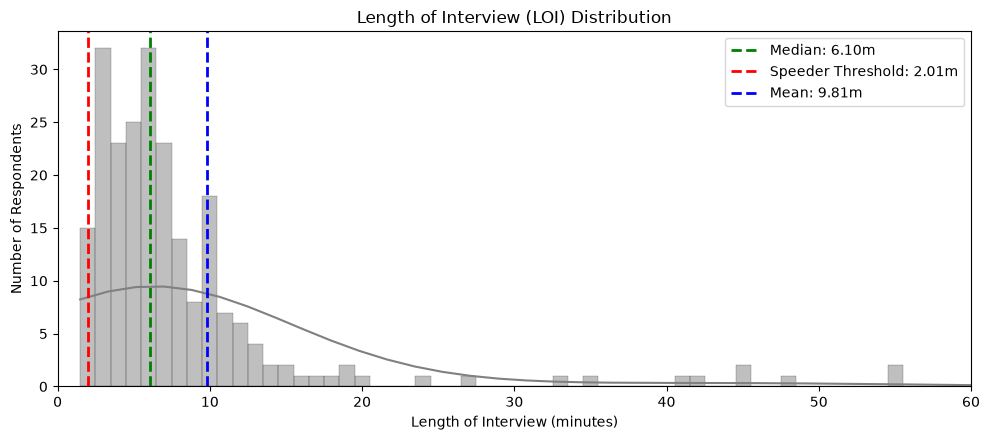

In [9]:
# visualize LOI distribution and key benchmark statistics
plt.figure(figsize=(10, 4.5))
sns.histplot(loi_minutes, kde=True, binwidth=1, color="grey")

plt.axvline(median_loi, color='green', linestyle='--', linewidth=2, label=f'Median: {median_loi:.2f}m')
plt.axvline(speeder_threshold, color='red', linestyle='--', linewidth=2, label=f'Speeder Threshold: {speeder_threshold:.2f}m')
plt.axvline(mean_loi, color='blue', linestyle='--', linewidth=2, label=f'Mean: {mean_loi:.2f}m')

# set x-axis limit to 60 minutes to make the main distribution readable
plt.xlim(0, 60)

plt.title('Length of Interview (LOI) Distribution')
plt.xlabel('Length of Interview (minutes)')
plt.ylabel('Number of Respondents')
plt.legend()
plt.tight_layout()
plt.show()

Most interviews take under 15 minutes, with a few sessions lasting significantly longer. 

The distribution is strongly right-skewed. Therefore, using the median rather than the mean provides an outlier-robust baseline for defining the speeder threshold.

In [10]:
# Check: identify respondents completing in less than 33% of median time
is_speeder = loi_minutes < speeder_threshold
speeder_count = is_speeder.sum()

# Apply: filter out speeders and reset index
df = df[~is_speeder].reset_index(drop=True)

n_after_speeder = df.shape[0]
attrition_after_speeder = round(speeder_count / raw_n * 100, 2)

# Print results
print(f"Median study duration: {median_loi:.2f} minutes")
print(f"Speeder threshold (33% of median): {speeder_threshold:.2f} minutes")
print(f"Speeders identified and removed: {speeder_count}")
print(f"Attrition (%): {attrition_after_speeder:.2f}")
print(f"Sessions remaining in dataset: {n_after_speeder}")

Median study duration: 6.10 minutes
Speeder threshold (33% of median): 2.01 minutes
Speeders identified and removed: 11
Attrition (%): 4.80
Sessions remaining in dataset: 218


In [11]:
#Double-check: inspect the final result
loi_minutes_fin = pd.to_timedelta(df['Study time']).dt.total_seconds() / 60
print (f'Min LOI: {loi_minutes_fin.min():.2f}\nMedian LOI: {loi_minutes_fin.median():.2f}')

Min LOI: 2.03
Median LOI: 6.32


Now the min LOI is 2.03 which means that all the sessions shorter than Speeder threshold have been successfully removed.

### 3. Geographic Targeting Check
The core market for the product was the Netherlands. Hence, the study strictly targeted contributors residing in this country. 

Below, I verify that 100% of participants match the target market geography and that no proxy/VPN leaks or cross-border contributors were included. To apply this check, I audit the `'Country'` column and filter out any non-Netherlands records.

In [12]:
# Pre-check: inspect missing values and unique values to check if there are any sessions outside the Netherlands
print (f"Missing values count: {df['Country'].isna().sum()}")
print (f"Unique values: {df['Country'].value_counts().to_string()}")

Missing values count: 0
Unique values: Country
Netherlands    214
Germany          2
Portugal         1
France           1


In [13]:
#Check: flag any records outside the Netherlands (case-insensitive & trimmed)
TARGET_COUNTRY = 'Netherlands'
is_invalid_geo = df['Country'].str.strip().str.lower() != TARGET_COUNTRY.lower()
is_invalid_geo_count = is_invalid_geo.sum()

#Apply: filter out invalid records
df = df[~is_invalid_geo].reset_index(drop = True)

n_after_invalid_geo = df.shape[0]
attrition_after_invalid_geo = round(is_invalid_geo_count / raw_n  * 100, 2)

#Print results
print(f"Target country: {TARGET_COUNTRY}")
print(f"Non-target geographic records removed: {is_invalid_geo_count}")
print(f"Attrition (%): {attrition_after_invalid_geo:.2f}")
print(f"Rows remaining in dataset: {n_after_invalid_geo}")

Target country: Netherlands
Non-target geographic records removed: 4
Attrition (%): 1.75
Rows remaining in dataset: 214


In [14]:
#Double-check: inspect the final result
print (f"Unique values: {df['Country'].value_counts().to_string()}")

Unique values: Country
Netherlands    214


Now all the interviews are from the Netherlands which means that all the sessions from other countries have been successfully removed.

### 4. Age Criteria Check (18–65 years)
The target audience criteria for this research were defined as adults aged **18 to 65**.


Below, I audit the reported age distribution to ensure that no underage contributors (<18) or out-of-scope age groups (>65) entered the sample. To do so, I validate the `'Q2. How old are you? (Please enter your age in full years) Answer'` column.

In [15]:
#define column name, minimum and maximum age borders
AGE_COL = 'Q2. How old are you? (Please enter your age in full years) Answer'
MIN_AGE = 18
MAX_AGE = 65

In [16]:
# Pre-check: inspect data type and missing values
print (f"Missing values count: {df[AGE_COL].isna().sum()}")
print (f"Data Type is: {df[AGE_COL].dtypes}")
print (f"Observed age range: {df[AGE_COL].min()} - {df[AGE_COL].max()} years")

Missing values count: 0
Data Type is: str
Observed age range: 16 - The only yyyyy that matters to us today was that  years


The column contains non-numeric values. For downstream analysis, I coerce non-numeric entries to NaN, filter out non-compliant sessions, and cast the validated values to integers.

In [17]:
#parse age to numeric, non-numeric entries are to be coerced to NaN. New column to be created for further work with it
df['age'] = pd.to_numeric (df[AGE_COL].astype(str).str.strip(), errors = 'coerce')
print (f'Data type after parsing: {df['age'].dtypes}\nNan count: {df['age'].isna().sum()}')


Data type after parsing: float64
Nan count: 1


In [18]:
#Check: define invalid condition and count invalid records.
is_invalid_age = (df["age"].isna()) | (~df["age"].between (MIN_AGE, MAX_AGE, inclusive = 'both'))
is_invalid_age_count = is_invalid_age.sum()

#Apply: filter out invalid age records and cast data type to integer
df = df[~is_invalid_age].reset_index(drop = True)
df['age'] = df['age'].astype(int)

n_after_invalid_age = df.shape[0]
attrition_after_invalid_age = round(is_invalid_age_count / raw_n * 100, 2)

#Print results
print(f"Target age: {MIN_AGE}-{MAX_AGE} years")
print(f"Non-target age records removed: {is_invalid_age_count}")
print(f"Attrition (%): {attrition_after_invalid_age:.2f}")
print(f"Rows remaining in dataset: {n_after_invalid_age}")

Target age: 18-65 years
Non-target age records removed: 6
Attrition (%): 2.62
Rows remaining in dataset: 208


In [19]:
#Double-check: inspect the final result
print (f"Current age bracket in the dataset: {df['age'].min()}-{df['age'].max()} years")

Current age bracket in the dataset: 18-65 years


The age bracket is now strictly 18–65 years, confirming that out-of-scope sessions have been successfully removed. Additionally, a standardized integer column 'age' is available for demographic analysis in future steps.

### 5. Satisficers / Avoiders

We evaluate two behavioral edge cases in multi-select screening:
- **Satisficers:** fraudulent respondents who select every single option ("Select All" behavior) to maximize qualification chances and claim the incentive.
- **Avoiders:** respondents selecting 0 substantive options (e.g., choosing "None of these"), demonstrating either zero target activity engagement or low-effort survey completion.

Below, I audit response patterns across the 10 substantive behavioral options in Q1 to test whether selecting all or zero options represents statistical outliers, and filter out inattentive sessions.

In [20]:
#look at all the cols starting with Q1.
q1_all_cols = [c for c in df.columns if c.startswith("Q1. Which of the following have you done in the last 12 months, even if only once?")]
q1_all_cols

['Q1. Which of the following have you done in the last 12 months, even if only once? Purchased access to online video games',
 'Q1. Which of the following have you done in the last 12 months, even if only once? Made in-game purchases or bought loot boxes',
 'Q1. Which of the following have you done in the last 12 months, even if only once? Deposited funds to cryptocurrency exchanges or digital wallets',
 'Q1. Which of the following have you done in the last 12 months, even if only once? Purchased airline tickets online',
 'Q1. Which of the following have you done in the last 12 months, even if only once? Booked travel accommodations online',
 'Q1. Which of the following have you done in the last 12 months, even if only once? Deposited funds to online investment or brokerage accounts',
 'Q1. Which of the following have you done in the last 12 months, even if only once? Purchased online educational courses or webinars',
 'Q1. Which of the following have you done in the last 12 months, ev

In [21]:
#pick only substantive cals and count them
q1_substantive_cols = [c for c in q1_all_cols if not c.endswith("None of these")]
substantive_cols_count = len(q1_substantive_cols)
substantive_cols_count

10

In [22]:
#Pre-check: inspect distribution of selected options count per respondent and identify if those selected all options are outliers indeed.
q1_selected_counts = df[q1_substantive_cols].notna().sum(axis=1)

q1_selected_counts_mean = q1_selected_counts.mean()
q1_selected_counts_std = q1_selected_counts.std()
z_scores = (q1_selected_counts - q1_selected_counts_mean) / q1_selected_counts_std

print (f'Distribution of selected options count(%):\n{q1_selected_counts.value_counts(normalize=True).mul(100).round(2).sort_index()}\n')
print(f"Z-score for {substantive_cols_count} options selected:  {(substantive_cols_count - q1_selected_counts_mean) / q1_selected_counts_std:.2f} (|Z| > 2.0 is an outlier)")
print(f"Z-score for 0 optionsselected:  {(0 - q1_selected_counts_mean) / q1_selected_counts_std:.2f} (|Z| > 2.0 is an outlier)")


Distribution of selected options count(%):
0      0.48
1      6.25
2      7.69
3     19.23
4     20.19
5     11.54
6     12.50
7      8.65
8      6.25
9      3.37
10     3.85
Name: proportion, dtype: float64

Z-score for 10 options selected:  2.30 (|Z| > 2.0 is an outlier)
Z-score for 0 optionsselected:  -2.06 (|Z| > 2.0 is an outlier)


The vast majority of respondents selected between 3 and 6 options out of 10.
Only 3.85% selected all 10 options, representing an extreme behavioral pattern. Claiming to have completed all 10 diverse actions within the past 12 months is statistically anomalous (|Z| = 2.30, p < 0.05). Therefore, these sessions are classified as outliers.

Additionally, respondents with 0 options selected are flagged as incomplete submissions. Below, I remove both edge cases from the analytical sample.

In [23]:
#Check: flag outliers
is_q1_outlier= (q1_selected_counts == substantive_cols_count) | (q1_selected_counts == 0)
q1_outliers_count = is_q1_outlier.sum()

#Apply: filter out the outliers
df = df[~is_q1_outlier].reset_index(drop = True)

n_after_q1_outliers = df.shape[0]
attrition_after_q1_outliers= round(q1_outliers_count / raw_n * 100,2)

#Print results
print(f"Outliers removed (all or nothing selected): {q1_outliers_count}")
print(f"Attrition (%): {attrition_after_q1_outliers:.2f}")
print(f"Rows remaining in dataset: {n_after_q1_outliers}")

Outliers removed (all or nothing selected): 9
Attrition (%): 3.93
Rows remaining in dataset: 199


In [24]:
#Double-check: inspect the final result
q1_selected_counts_fin = df[q1_substantive_cols].notna().sum(axis=1)
print (f"Current selected option count bracket in the dataset: {q1_selected_counts_fin.min()}-{q1_selected_counts_fin.max()}")

Current selected option count bracket in the dataset: 1-9


The selected option count range is now 1–9 options, confirming that all edge cases have been successfully removed.

### 6. Target Audience Screening
To qualify for the prototype study, respondents must have performed at least one of the following financial actions in the past 12 months:
1. Deposited funds to cryptocurrency exchanges or digital wallets
2. Deposited funds to online investment or brokerage accounts
3. Deposited funds to online trading or contract platforms

Below, I audit the multi-select options in Q1 to ensure non-target respondents are properly filtered out.

In [25]:
TARGET_COLS = [
    'Q1. Which of the following have you done in the last 12 months, even if only once? Deposited funds to cryptocurrency exchanges or digital wallets', 
    'Q1. Which of the following have you done in the last 12 months, even if only once? Deposited funds to online investment or brokerage accounts', 
    'Q1. Which of the following have you done in the last 12 months, even if only once? Deposited funds to online trading or contract platforms']

In [26]:
#Check: flag non-target audience. At least one option should be selected.
is_non_target_audience = df[TARGET_COLS].isna().all(axis = 1)
non_target_audience_count = (is_non_target_audience).sum()

#Apply: filter-out the sessions with non-target audience
df = df[~is_non_target_audience].reset_index (drop = True)

n_after_non_target_audience = df.shape[0]
attrition_after_non_target_audience = round(non_target_audience_count / raw_n * 100,2)

#Print results
print (f'Non-target sessions removed: {non_target_audience_count}')
print(f"Attrition (%): {attrition_after_non_target_audience:.2f}")
print(f"Rows remaining in dataset: {n_after_non_target_audience}")

Non-target sessions removed: 1
Attrition (%): 0.44
Rows remaining in dataset: 198


In [27]:
#Double-check: inspect the final result
non_target_remaining =(~df[TARGET_COLS].notna().any(axis = 1)).sum()
print(f"Non-target sessions remaining: {non_target_remaining}")

Non-target sessions remaining: 0


Currently, there are no sessions without at least one selected target option, confirming that all non-target respondents have been successfully removed.

### 7. Survey Completion Check
To analyse only completed sessions, I am going to filter out all sessions where the last question (Q43) has no answer

In [28]:
FINAL_Q = [c for c in df.columns if c.startswith ('Q43.')][0]

In [29]:
#Check: identify incomplete sessions
is_incomplete_session = df[FINAL_Q].isna()
incomplete_sessions_count = is_incomplete_session.sum()

#Apply: filter out all incomplete sessions
df = df[~is_incomplete_session].reset_index(drop = True)

n_after_incomplete_sessions = df.shape[0]
attrition_after_incomplete_sessions = round (incomplete_sessions_count/ raw_n * 100,2)

#Print results
print (f'Incomplete sessions removed: {incomplete_sessions_count}')
print(f"Attrition (%): {attrition_after_incomplete_sessions:.2f}")
print(f"Rows remaining in dataset: {n_after_incomplete_sessions}")

Incomplete sessions removed: 0
Attrition (%): 0.00
Rows remaining in dataset: 198


In [30]:
#Double-check: inspect the final result
incomplete_remaining =df[FINAL_Q].isna().sum()
print(f"Incomplete sessions remaining: {incomplete_remaining}")

Incomplete sessions remaining: 0


Currently, there are no incomplete sessions.

### 8. Data Hygiene Summary and Export
Below, I build a consolidated sample attrition table summarizing each validation step, the volume of excluded records, and export the final cleaned database.

In [31]:
# Attrition Summary
attrition_summary = pd.DataFrame([
    {'Step': '1. Raw Sample', 'Excluded': 0, 'Remaining': raw_n, 'Attrition (%)': 0.0},
    {'Step': '2. Speeders Filter (<33% median LOI)', 'Excluded': speeder_count, 'Remaining': n_after_speeder, 'Attrition (%)': attrition_after_speeder},
    {'Step': '3. Geographic Targeting (Non-NL)', 'Excluded': is_invalid_geo_count, 'Remaining': n_after_invalid_geo, 'Attrition (%)': attrition_after_invalid_geo},
    {'Step': '4. Age Screening (<18, >65)', 'Excluded': is_invalid_age_count, 'Remaining': n_after_invalid_age, 'Attrition (%)': attrition_after_invalid_age},
    {'Step': '5. Straightliners / Satisficers (0 or 10 options)', 'Excluded': q1_outliers_count, 'Remaining': n_after_q1_outliers, 'Attrition (%)': attrition_after_q1_outliers},
    {'Step': '6. Target Audience Qualification (Q1 Screener)', 'Excluded': non_target_audience_count, 'Remaining': n_after_non_target_audience, 'Attrition (%)': attrition_after_non_target_audience},
    {'Step': '7. Survey Completion (Q43 Missing)', 'Excluded': incomplete_sessions_count, 'Remaining': n_after_incomplete_sessions, 'Attrition (%)': attrition_after_incomplete_sessions},
])

total_sessions_removed = speeder_count + is_invalid_geo_count + is_invalid_age_count + q1_outliers_count + non_target_audience_count + incomplete_sessions_count
total_attrition = round(total_sessions_removed / raw_n * 100, 2)

print(f"Median LOI: {median_loi:.2f} minutes")
print(f"In total {total_sessions_removed} sessions removed out of {raw_n}")
print(f"Total attrition: {total_attrition}%")

print("\nATTRITION SUMMARY")
print(attrition_summary.to_string(index=False))

# Export clean analytical dataset for subsequent analysis notebooks
CLEAN_DATA_PATH = '../data/P1_FTD_cleaned_sample.csv'
df.to_csv(CLEAN_DATA_PATH, index=False)

print(f"\nClean analytical dataset successfully saved to: '{CLEAN_DATA_PATH}'")
print(f"Final cohort size: {df.shape[0]} rows, {df.shape[1]} columns")

Median LOI: 6.10 minutes
In total 31 sessions removed out of 229
Total attrition: 13.54%

ATTRITION SUMMARY
                                             Step  Excluded  Remaining  Attrition (%)
                                    1. Raw Sample         0        229           0.00
             2. Speeders Filter (<33% median LOI)        11        218           4.80
                 3. Geographic Targeting (Non-NL)         4        214           1.75
                      4. Age Screening (<18, >65)         6        208           2.62
5. Straightliners / Satisficers (0 or 10 options)         9        199           3.93
   6. Target Audience Qualification (Q1 Screener)         1        198           0.44
               7. Survey Completion (Q43 Missing)         0        198           0.00

Clean analytical dataset successfully saved to: '../data/P1_FTD_cleaned_sample.csv'
Final cohort size: 198 rows, 175 columns
